# Minimum-Snap Motion Primitives in JAX (Slides 16–17)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arunkumar-singh/drone_course_repo/blob/main/tutorials/quadrotor_min_snap_primitives_jax_colab.ipynb)

A bare-minimal, standalone companion notebook covering **only** the Slide 16–17 degree-7 minimum-snap boundary-value solver, trajectory evaluation in normalized time $u = t / T \in [0, 1]$, and vectorized batch sampling with `jax.vmap` over $(x_f, v_f, T)$.

1. **Block 1 (Slides 16–17)**: Single-primitive coefficient solve via `M_inv = jnp.linalg.inv(M)` and evaluation of $(t, p, v, a, j)$ on a 1D moving-state example.
2. **Block 2 (`jax.vmap`)**: Reusing the exact same solver and evaluator over batches of sampled $(x_f, v_f, T)$ — a 34-candidate 2D fan (Slide 19) and a varying-duration sweep (Slide 20).


In [1]:
import importlib.util
import subprocess
import sys

_missing = []
try:
    import jax
    import jax.numpy as jnp
except ImportError:
    _missing.append("jax")

if importlib.util.find_spec("matplotlib") is None:
    _missing.append("matplotlib")

if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

# Preserve full float32 precision on CUDA GPUs (disable TF32 10-bit matmul rounding)
jax.config.update("jax_default_matmul_precision", "highest")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "legend.fontsize": 8.5,
})

print(f"JAX version: {jax.__version__}")
print(f"Backend:     {jax.default_backend()}")
print(f"Devices:     {jax.devices()}")


JAX version: 0.6.2


Backend:     gpu
Devices:     [CudaDevice(id=0)]


---
## Block 1: Slide 16–17 Single Minimum-Snap Primitive

In normalized time $u = t / T \in [0, 1]$, a degree-7 minimum-snap polynomial splits into the known initial-motion cubic $g(u)$ and four unknown higher-order terms:

$$
g(u) = x_0 + T v_0 u + \tfrac{1}{2} T^2 a_0 u^2 + \tfrac{1}{6} T^3 j_0 u^3,
\qquad
q(u) = g(u) + b_4 u^4 + b_5 u^5 + b_6 u^6 + b_7 u^7.
$$

Enforcing the terminal state $(x_f, v_f, a_f, j_f)$ at $u = 1$ yields the **final residuals** (Slide 16):

$$
\begin{aligned}
\rho_0 &= x_f - x_0 - T v_0 - \tfrac{1}{2} T^2 a_0 - \tfrac{1}{6} T^3 j_0, \\
\rho_1 &= T v_f - T v_0 - T^2 a_0 - \tfrac{1}{2} T^3 j_0, \\
\rho_2 &= T^2 a_f - T^2 a_0 - T^3 j_0, \\
\rho_3 &= T^3 j_f - T^3 j_0.
\end{aligned}
$$

Evaluating the derivatives of $b_4 u^4 + b_5 u^5 + b_6 u^6 + b_7 u^7$ at $u = 1$ gives the constant $4 \times 4$ system (Slide 17), solved once with `M_inv = jnp.linalg.inv(M)`:

$$
\underbrace{\begin{bmatrix}
1 & 1 & 1 & 1 \\
4 & 5 & 6 & 7 \\
12 & 20 & 30 & 42 \\
24 & 60 & 120 & 210
\end{bmatrix}}_{M}
\begin{bmatrix} b_4 \\ b_5 \\ b_6 \\ b_7 \end{bmatrix}
=
\begin{bmatrix} \rho_0 \\ \rho_1 \\ \rho_2 \\ \rho_3 \end{bmatrix}
\quad\Longrightarrow\quad
\begin{bmatrix} b_4 \\ b_5 \\ b_6 \\ b_7 \end{bmatrix}
= M^{-1} \rho.
$$

Physical derivatives follow from the chain rule $x^{(\ell)}(t) = T^{-\ell} q^{(\ell)}(u)$. Because `M_inv` multiplies along axis `0`, the exact same `solve_min_snap` and `eval_primitive` work unchanged for 1D scalars (`(8,)`) and $D$-dimensional vectors (`(8, D)`).


In [2]:
M = jnp.array([
    [1.0, 1.0, 1.0, 1.0],
    [4.0, 5.0, 6.0, 7.0],
    [12.0, 20.0, 30.0, 42.0],
    [24.0, 60.0, 120.0, 210.0],
])
M_inv = jnp.linalg.inv(M)


def solve_min_snap(x0, v0, a0, j0, xf, vf, af, jf, T):
    b0123 = jnp.array([x0, T * v0, 0.5 * T**2 * a0, (1.0 / 6.0) * T**3 * j0])
    rho = jnp.array([
        xf - x0 - T * v0 - 0.5 * T**2 * a0 - (1.0 / 6.0) * T**3 * j0,
        T * vf - T * v0 - T**2 * a0 - 0.5 * T**3 * j0,
        T**2 * af - T**2 * a0 - T**3 * j0,
        T**3 * jf - T**3 * j0,
    ])
    b4567 = M_inv @ rho
    return jnp.concatenate([b0123, b4567], axis=0)


def eval_primitive(coeffs, T, u):
    z, o = jnp.zeros_like(u), jnp.ones_like(u)
    Up = jnp.stack([o, u, u**2, u**3, u**4, u**5, u**6, u**7], axis=-1)
    Uv = jnp.stack([z, o, 2 * u, 3 * u**2, 4 * u**3, 5 * u**4, 6 * u**5, 7 * u**6], axis=-1) / T
    Ua = jnp.stack([z, z, 2 * o, 6 * u, 12 * u**2, 20 * u**3, 30 * u**4, 42 * u**5], axis=-1) / T**2
    Uj = jnp.stack([z, z, z, 6 * o, 24 * u, 60 * u**2, 120 * u**3, 210 * u**4], axis=-1) / T**3
    return T * u, Up @ coeffs, Uv @ coeffs, Ua @ coeffs, Uj @ coeffs


coeffs shape: (8,)
t = 0.0 s -> p=0.000000, v=1.000000, a=0.200000, j=-0.300000
t = 2.0 s -> p=2.499992, v=0.500015, a=0.000000, j=0.000000


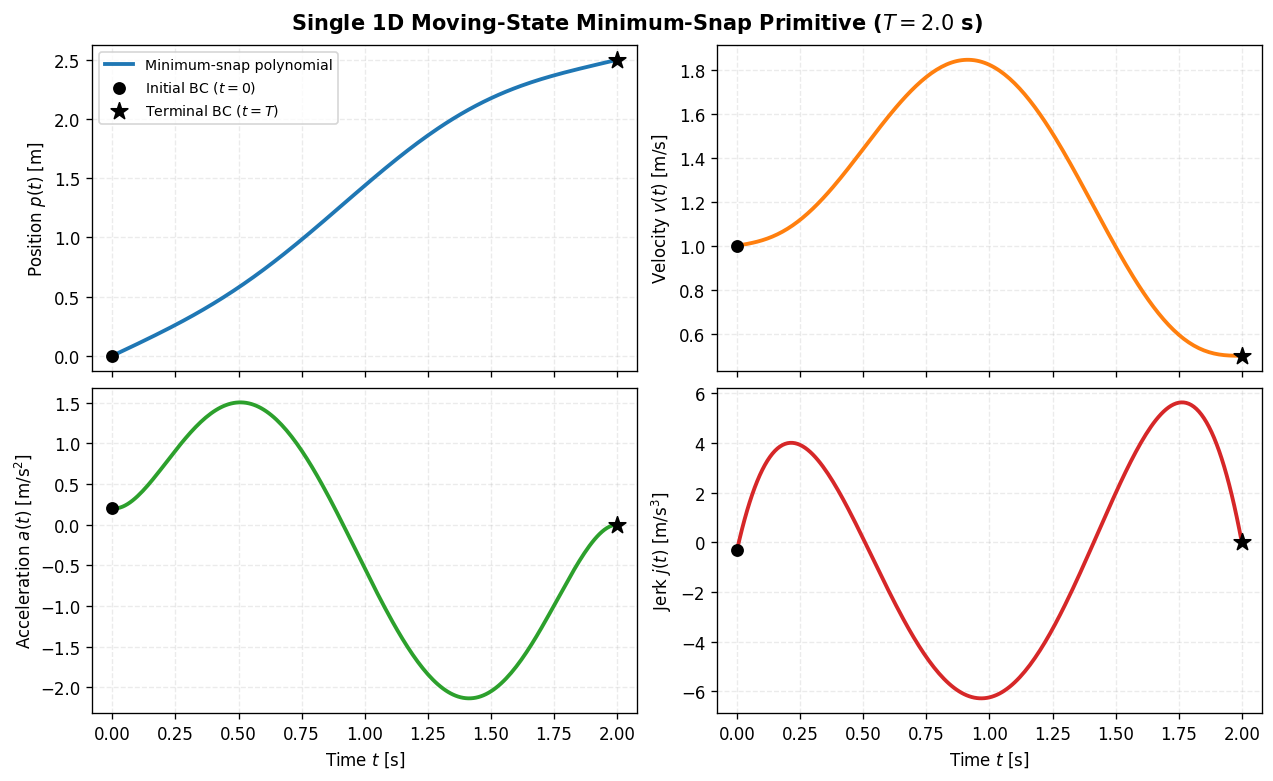

In [3]:
x0, v0, a0, j0 = 0.0, 1.0, 0.2, -0.3
xf, vf, af, jf = 2.5, 0.5, 0.0, 0.0
T = 2.0

coeffs = solve_min_snap(x0, v0, a0, j0, xf, vf, af, jf, T)
u = jnp.linspace(0.0, 1.0, 201)
t, p, v, a, j = eval_primitive(coeffs, T, u)

print(f"coeffs shape: {coeffs.shape}")
print(f"t = 0.0 s -> p={float(p[0]):.6f}, v={float(v[0]):.6f}, a={float(a[0]):.6f}, j={float(j[0]):.6f}")
print(f"t = {T:.1f} s -> p={float(p[-1]):.6f}, v={float(v[-1]):.6f}, a={float(a[-1]):.6f}, j={float(j[-1]):.6f}")

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), sharex=True, constrained_layout=True)
series = [
    (p, "Position $p(t)$ [m]", x0, xf, "#1f77b4"),
    (v, "Velocity $v(t)$ [m/s]", v0, vf, "#ff7f0e"),
    (a, "Acceleration $a(t)$ [m/s$^2$]", a0, af, "#2ca02c"),
    (j, "Jerk $j(t)$ [m/s$^3$]", j0, jf, "#d62728"),
]

for idx, (ax, (y, ylabel, y0_val, yf_val, color)) in enumerate(zip(axes.flat, series)):
    ax.plot(t, y, color=color, lw=2.3, label="Minimum-snap polynomial")
    ax.scatter([0.0], [y0_val], color="black", s=45, zorder=5, label="Initial BC ($t=0$)")
    ax.scatter([T], [yf_val], color="black", marker="*", s=110, zorder=5, label="Terminal BC ($t=T$)")
    ax.set_ylabel(ylabel)
    ax.set_xlim(-0.08, T + 0.08)
    if idx == 0:
        ax.legend(loc="upper left", frameon=True)

axes[1, 0].set_xlabel("Time $t$ [s]")
axes[1, 1].set_xlabel("Time $t$ [s]")
fig.suptitle("Single 1D Moving-State Minimum-Snap Primitive ($T = 2.0$ s)", fontsize=12.5, fontweight="bold")
plt.show()


---
## Block 2: Batch Sampling with `jax.vmap` over $(x_f, v_f, T)$

Without changing a single line of `solve_min_snap` or `eval_primitive`, `jax.vmap` maps them across a batch of $B$ sampled terminal states and durations:

```python
batch_solve = jax.jit(jax.vmap(solve_min_snap, in_axes=(None, None, None, None, 0, 0, None, None, 0)))
batch_eval  = jax.jit(jax.vmap(eval_primitive, in_axes=(0, 0, None)))
```

- `in_axes=(None, None, None, None, 0, 0, None, None, 0)` broadcasts the shared initial state $(x_0, v_0, a_0, j_0)$ and zero terminal $(a_f, j_f)$, while vectorizing along axis `0` of `(xf, vf, T)`.
- `batch_eval` evaluates all $B$ primitives in parallel over a shared normalized grid `u_grid` $\in [0, 1]$.

Below we call the **exact same** `batch_solve` and `batch_eval` on two sampling batches:
1. **Slide 19 2D candidate fan ($B = 34$, fixed $T = 2.0\,\text{s}$)**: 11 angles in $[-75^\circ, +75^\circ]$ $\times$ 3 distances $\{1.5, 2.0, 2.5\}\,\text{m}$ around the goal direction, plus 1 goal-stop candidate (`vf = [0, 0]`).
2. **Slide 20 duration sweep ($B = 4$, varying $T$)**: fixed terminal state `(xf=[3.0, 1.5], vf=[0.8, 0.0])` across $T \in \{1.2, 1.8, 2.5, 3.5\}\,\text{s}$ to show how $T$ enters through `vmap` and reshapes paths and peak velocities.


--- Batch 1: Slide 19 2D Candidate Fan (34 candidates) ---
Inputs -> xf_fan: (34, 2), vf_fan: (34, 2), T_fan: (34,)
Outputs -> coeffs_fan: (34, 8, 2), p_fan: (34, 101, 2), v_fan: (34, 101, 2)


Max terminal error -> pos: 3.05e-05, vel: 1.53e-04, acc: 2.75e-04, jerk: 2.59e-04

--- Batch 2: Varying-Duration Sweep (4 candidates) ---
Inputs -> xf_dur: (4, 2), vf_dur: (4, 2), T_dur: (4,)
Outputs -> coeffs_dur: (4, 8, 2), p_dur: (4, 101, 2), v_dur: (4, 101, 2)


Max terminal error -> pos: 2.67e-05, vel: 7.69e-05, acc: 7.55e-05, jerk: 3.33e-04


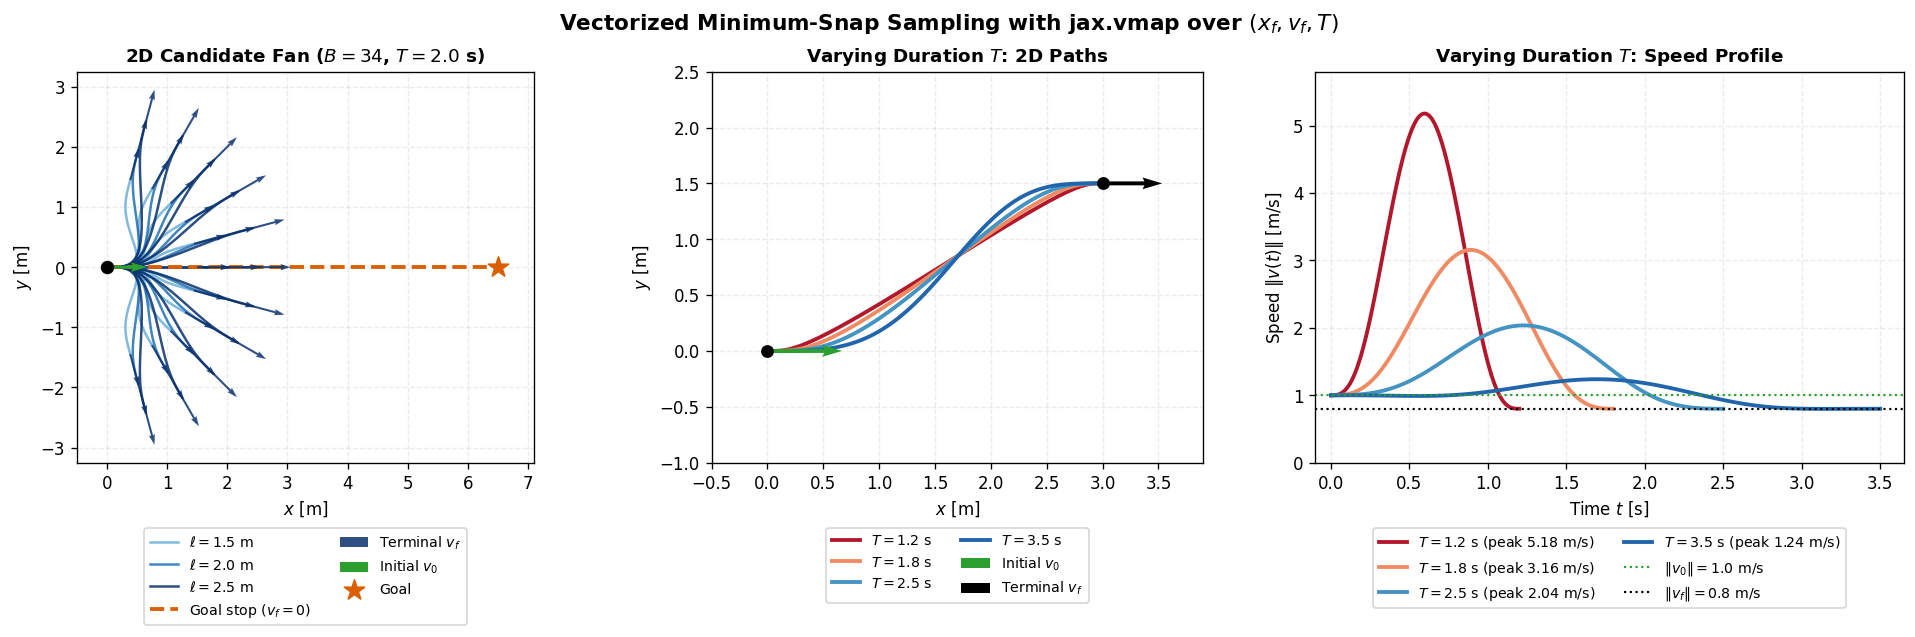

In [4]:
batch_solve = jax.jit(jax.vmap(solve_min_snap, in_axes=(None, None, None, None, 0, 0, None, None, 0)))
batch_eval = jax.jit(jax.vmap(eval_primitive, in_axes=(0, 0, None)))

p0 = jnp.array([0.0, 0.0])
v0 = jnp.array([1.0, 0.0])
a0 = jnp.array([0.0, 0.0])
j0 = jnp.array([0.0, 0.0])
af = jnp.array([0.0, 0.0])
jf = jnp.array([0.0, 0.0])
u_grid = jnp.linspace(0.0, 1.0, 101)

# 1) Slide 19 2D candidate fan (34 candidates, T = 2.0 s)
goal = jnp.array([6.5, 0.0])
theta_goal = jnp.arctan2(goal[1] - p0[1], goal[0] - p0[0])
angles = jnp.deg2rad(jnp.linspace(-75.0, 75.0, 11))
dists = jnp.array([1.5, 2.0, 2.5])
dist_grid, ang_grid = jnp.meshgrid(dists, angles, indexing="ij")
phi = theta_goal + ang_grid.reshape(-1)
dirs = jnp.stack([jnp.cos(phi), jnp.sin(phi)], axis=-1)

xf_fan = jnp.concatenate([p0 + dist_grid.reshape(-1, 1) * dirs, goal[None, :]], axis=0)
vf_fan = jnp.concatenate([1.0 * dirs, jnp.zeros((1, 2))], axis=0)
T_fan = jnp.full((34,), 2.0)

coeffs_fan = batch_solve(p0, v0, a0, j0, xf_fan, vf_fan, af, jf, T_fan)
t_fan, p_fan, v_fan, a_fan, j_fan = batch_eval(coeffs_fan, T_fan, u_grid)

# 2) Varying-duration batch (4 samples to same endpoint across T)
T_dur = jnp.array([1.2, 1.8, 2.5, 3.5])
xf_dur = jnp.repeat(jnp.array([[3.0, 1.5]]), T_dur.shape[0], axis=0)
vf_dur = jnp.repeat(jnp.array([[0.8, 0.0]]), T_dur.shape[0], axis=0)

coeffs_dur = batch_solve(p0, v0, a0, j0, xf_dur, vf_dur, af, jf, T_dur)
t_dur, p_dur, v_dur, a_dur, j_dur = batch_eval(coeffs_dur, T_dur, u_grid)
speed_dur = jnp.linalg.norm(v_dur, axis=-1)

print("--- Batch 1: Slide 19 2D Candidate Fan (34 candidates) ---")
print(f"Inputs -> xf_fan: {xf_fan.shape}, vf_fan: {vf_fan.shape}, T_fan: {T_fan.shape}")
print(f"Outputs -> coeffs_fan: {coeffs_fan.shape}, p_fan: {p_fan.shape}, v_fan: {v_fan.shape}")
print(
    f"Max terminal error -> pos: {float(jnp.max(jnp.abs(p_fan[:, -1] - xf_fan))):.2e}, "
    f"vel: {float(jnp.max(jnp.abs(v_fan[:, -1] - vf_fan))):.2e}, "
    f"acc: {float(jnp.max(jnp.abs(a_fan[:, -1] - af))):.2e}, "
    f"jerk: {float(jnp.max(jnp.abs(j_fan[:, -1] - jf))):.2e}"
)

print("\n--- Batch 2: Varying-Duration Sweep (4 candidates) ---")
print(f"Inputs -> xf_dur: {xf_dur.shape}, vf_dur: {vf_dur.shape}, T_dur: {T_dur.shape}")
print(f"Outputs -> coeffs_dur: {coeffs_dur.shape}, p_dur: {p_dur.shape}, v_dur: {v_dur.shape}")
print(
    f"Max terminal error -> pos: {float(jnp.max(jnp.abs(p_dur[:, -1] - xf_dur))):.2e}, "
    f"vel: {float(jnp.max(jnp.abs(v_dur[:, -1] - vf_dur))):.2e}, "
    f"acc: {float(jnp.max(jnp.abs(a_dur[:, -1] - af))):.2e}, "
    f"jerk: {float(jnp.max(jnp.abs(j_dur[:, -1] - jf))):.2e}"
)

# Clean 1x3 visualization
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(16.0, 5.2), constrained_layout=True)

# Panel 1: 34-candidate 2D fan with terminal velocity quiver arrows
dist_colors = ["#6baed6", "#2171b5", "#08306b"]
for d_idx, (d_val, col) in enumerate(zip([1.5, 2.0, 2.5], dist_colors)):
    sl = slice(d_idx * 11, (d_idx + 1) * 11)
    for k in range(sl.start, sl.stop):
        lbl = f"$\ell = {d_val:.1f}$ m" if k == sl.start else None
        ax0.plot(p_fan[k, :, 0], p_fan[k, :, 1], color=col, lw=1.5, alpha=0.85, label=lbl)

ax0.plot(p_fan[33, :, 0], p_fan[33, :, 1], color="#d95f02", lw=2.3, ls="--", label="Goal stop ($v_f=0$)")
ax0.quiver(
    xf_fan[:33, 0], xf_fan[:33, 1],
    vf_fan[:33, 0], vf_fan[:33, 1],
    angles="xy", scale_units="xy", scale=1.8, width=0.0045,
    color="#08306b", alpha=0.85, zorder=5, label="Terminal $v_f$",
)
ax0.quiver(
    [p0[0]], [p0[1]], [v0[0]], [v0[1]],
    angles="xy", scale_units="xy", scale=1.5, width=0.007,
    color="#2ca02c", zorder=6, label="Initial $v_0$",
)
ax0.scatter([p0[0]], [p0[1]], color="black", s=50, zorder=7)
ax0.scatter([goal[0]], [goal[1]], color="#d95f02", marker="*", s=160, zorder=7, label="Goal")
ax0.set_aspect("equal", adjustable="box")
ax0.set_xlim(-0.5, 7.1)
ax0.set_ylim(-3.25, 3.25)
ax0.set_xlabel("$x$ [m]")
ax0.set_ylabel("$y$ [m]")
ax0.set_title("2D Candidate Fan ($B = 34$, $T = 2.0$ s)")
ax0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)

# Panels 2 & 3: Varying-duration XY paths and speed profiles
dur_colors = ["#b2182b", "#ef8a62", "#4393c3", "#2166ac"]
for k in range(T_dur.shape[0]):
    T_k = float(T_dur[k])
    v_peak = float(jnp.max(speed_dur[k]))
    col = dur_colors[k]
    ax1.plot(p_dur[k, :, 0], p_dur[k, :, 1], color=col, lw=2.3, label=f"$T = {T_k:.1f}$ s")
    ax2.plot(t_dur[k], speed_dur[k], color=col, lw=2.3, label=f"$T = {T_k:.1f}$ s (peak {v_peak:.2f} m/s)")

ax1.quiver(
    [p0[0]], [p0[1]], [v0[0]], [v0[1]],
    angles="xy", scale_units="xy", scale=1.5, width=0.008,
    color="#2ca02c", zorder=6, label="Initial $v_0$",
)
ax1.quiver(
    [xf_dur[0, 0]], [xf_dur[0, 1]], [vf_dur[0, 0]], [vf_dur[0, 1]],
    angles="xy", scale_units="xy", scale=1.5, width=0.008,
    color="black", zorder=6, label="Terminal $v_f$",
)
ax1.scatter([p0[0], xf_dur[0, 0]], [p0[1], xf_dur[0, 1]], color="black", s=45, zorder=7)
ax1.set_aspect("equal", adjustable="box")
ax1.set_xlim(-0.5, 3.9)
ax1.set_ylim(-1.0, 2.5)
ax1.set_xlabel("$x$ [m]")
ax1.set_ylabel("$y$ [m]")
ax1.set_title("Varying Duration $T$: 2D Paths")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)

ax2.axhline(float(jnp.linalg.norm(v0)), color="#2ca02c", ls=":", lw=1.3, label="$\|v_0\| = 1.0$ m/s")
ax2.axhline(float(jnp.linalg.norm(vf_dur[0])), color="black", ls=":", lw=1.3, label="$\|v_f\| = 0.8$ m/s")
ax2.set_xlim(-0.1, float(T_dur[-1]) + 0.15)
ax2.set_ylim(0.0, float(jnp.max(speed_dur)) * 1.12)
ax2.set_xlabel("Time $t$ [s]")
ax2.set_ylabel("Speed $\|v(t)\|$ [m/s]")
ax2.set_title("Varying Duration $T$: Speed Profile")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)

fig.suptitle("Vectorized Minimum-Snap Sampling with jax.vmap over $(x_f, v_f, T)$", fontsize=13, fontweight="bold")
plt.show()
